In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Processed data folder exists:", DATA_DIR.exists())
print("Reports folder exists:", REPORTS_DIR.exists())

Project root: C:\Users\asus\mutual-funds-analysis
Processed data folder exists: True
Reports folder exists: True


In [2]:
def load_csv(pattern):
    file = next(DATA_DIR.glob(pattern), None)
    if file is None:
        raise FileNotFoundError(f"No file found for: {pattern}")
    return pd.read_csv(file)

funds = load_csv("*fund_master*.csv")
nav = load_csv("*nav_history*.csv")
transactions = load_csv("*investor_transactions*.csv")
holdings = load_csv("*portfolio_holdings*.csv")
sip = load_csv("*monthly_sip_inflows*.csv")
performance = load_csv("*scheme_performance*.csv")

print("Funds:", funds.shape)
print("NAV history:", nav.shape)
print("Transactions:", transactions.shape)
print("Portfolio holdings:", holdings.shape)
print("SIP data:", sip.shape)
print("Scheme performance:", performance.shape)

Funds: (40, 15)
NAV history: (46000, 3)
Transactions: (32778, 13)
Portfolio holdings: (322, 8)
SIP data: (48, 6)
Scheme performance: (40, 19)


In [3]:
# Risk–Return Analysis using reported scheme performance

risk_return = performance[
    [
        "scheme_name",
        "category",
        "return_1yr_pct",
        "std_dev_ann_pct",
        "sharpe_ratio",
        "risk_grade"
    ]
].copy()

risk_return = risk_return.dropna(
    subset=["return_1yr_pct", "std_dev_ann_pct"]
)

# Classify funds using median return and median risk
median_return = risk_return["return_1yr_pct"].median()
median_risk = risk_return["std_dev_ann_pct"].median()

risk_return["risk_return_group"] = np.select(
    [
        (risk_return["return_1yr_pct"] >= median_return) &
        (risk_return["std_dev_ann_pct"] < median_risk),

        (risk_return["return_1yr_pct"] >= median_return) &
        (risk_return["std_dev_ann_pct"] >= median_risk),

        (risk_return["return_1yr_pct"] < median_return) &
        (risk_return["std_dev_ann_pct"] < median_risk)
    ],
    [
        "Higher Return - Lower Risk",
        "Higher Return - Higher Risk",
        "Lower Return - Lower Risk"
    ],
    default="Lower Return - Higher Risk"
)

display(
    risk_return.sort_values(
        "return_1yr_pct", ascending=False
    ).head(10).round(2)
)

print("\nRisk–Return group counts:")
print(risk_return["risk_return_group"].value_counts())

print("\nMedian 1-year return:", round(median_return, 2), "%")
print("Median annualized risk:", round(median_risk, 2), "%")

,scheme_name,category,return_1yr_pct,std_dev_ann_pct,sharpe_ratio,risk_grade,risk_return_group
29,ABSL Small Cap Fund - Regular - Growth,Small Cap,24.93,25.0,0.90,Very High,Higher Return - Higher Risk
2,SBI Small Cap Fund - Regular Plan - Growth,Small Cap,24.56,25.0,0.94,Very High,Higher Return - Higher Risk
27,Axis Small Cap Fund - Regular - Growth,Small Cap,21.97,25.0,0.84,Very High,Higher Return - Higher Risk
17,Nippon India Small Cap Fund - Regular - Growth,Small Cap,21.30,25.0,0.81,Very High,Higher Return - Higher Risk
3,SBI Small Cap Fund - Direct Plan - Growth,Small Cap,20.59,25.0,0.93,Very High,Higher Return - Higher Risk
39,DSP Small Cap Fund - Regular - Growth,Small Cap,20.20,25.0,0.80,Very High,Higher Return - Higher Risk
8,HDFC Mid-Cap Opportunities Fund - Direct - Growth,Mid Cap,19.98,19.0,0.80,High,Higher Return - Higher Risk
33,UTI Flexi Cap Fund - Regular - Growth,Flexi Cap,17.43,16.0,0.96,Moderately High,Higher Return - Higher Risk
21,Kotak Emerging Equity Fund - Regular - Growth,Mid Cap,17.12,19.0,0.96,High,Higher Return - Higher Risk
13,ICICI Pru Value Discovery Fund - Regular - Growth,Value,16.67,15.0,0.98,Moderately High,Higher Return - Higher Risk



Risk–Return group counts:
risk_return_group
Higher Return - Higher Risk    20
Lower Return - Higher Risk     12
Lower Return - Lower Risk       8
Name: count, dtype: int64

Median 1-year return: 14.62 %
Median annualized risk: 14.0 %


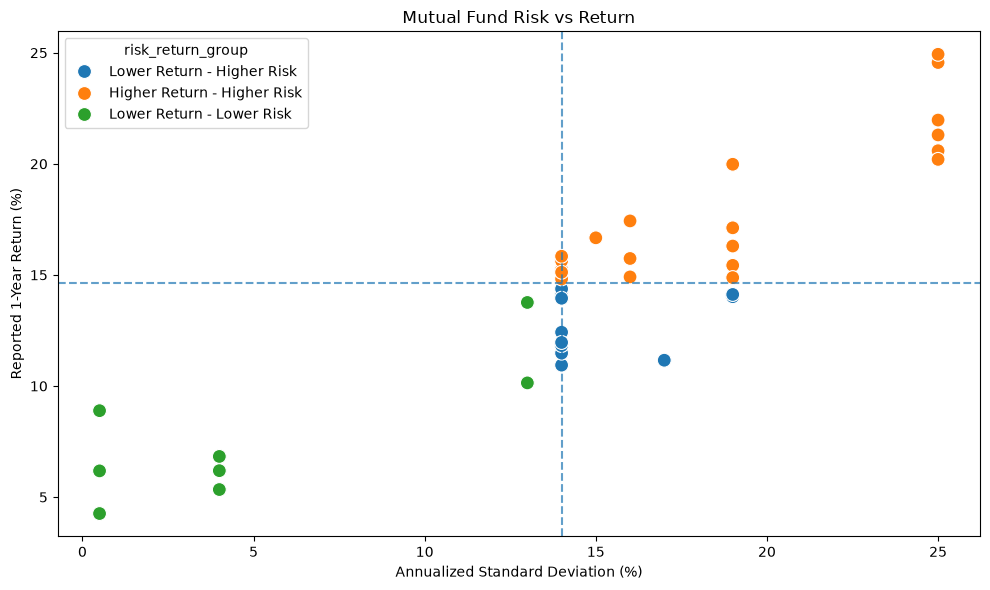

In [4]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=risk_return,
    x="std_dev_ann_pct",
    y="return_1yr_pct",
    hue="risk_return_group",
    s=100
)

plt.axvline(median_risk, linestyle="--", alpha=0.7)
plt.axhline(median_return, linestyle="--", alpha=0.7)

plt.title("Mutual Fund Risk vs Return")
plt.xlabel("Annualized Standard Deviation (%)")
plt.ylabel("Reported 1-Year Return (%)")
plt.tight_layout()
plt.show()

In [5]:
output_file = REPORTS_DIR / "risk_return_analysis.csv"

risk_return.to_csv(output_file, index=False)

print("Saved successfully:", output_file)
print("Total funds analyzed:", len(risk_return))

Saved successfully: C:\Users\asus\mutual-funds-analysis\reports\risk_return_analysis.csv
Total funds analyzed: 40


In [6]:
category_analysis = (
    performance.groupby("category")
    .agg(
        fund_count=("scheme_name", "count"),
        avg_1yr_return_pct=("return_1yr_pct", "mean"),
        avg_3yr_return_pct=("return_3yr_pct", "mean"),
        avg_risk_pct=("std_dev_ann_pct", "mean"),
        avg_sharpe_ratio=("sharpe_ratio", "mean")
    )
    .reset_index()
    .sort_values("avg_1yr_return_pct", ascending=False)
)

display(category_analysis.round(2))

category_analysis.to_csv(
    REPORTS_DIR / "category_risk_return_analysis.csv",
    index=False
)

print("Saved:", REPORTS_DIR / "category_risk_return_analysis.csv")

,category,fund_count,avg_1yr_return_pct,avg_3yr_return_pct,avg_risk_pct,avg_sharpe_ratio
10,Small Cap,6,22.26,21.69,25.0,0.87
11,Value,1,16.67,14.76,15.0,0.98
1,Flexi Cap,2,16.58,15.50,16.0,0.97
8,Mid Cap,7,15.98,16.59,19.0,0.87
5,Large & Mid Cap,1,14.91,14.56,16.0,0.91
3,Index,1,13.76,12.10,13.0,0.93
6,Large Cap,14,13.72,12.99,14.0,0.93
0,ELSS,1,11.16,13.58,17.0,0.80
4,Index/ETF,1,10.14,11.77,13.0,0.91
9,Short Duration,1,6.83,7.37,4.0,1.84


Saved: C:\Users\asus\mutual-funds-analysis\reports\category_risk_return_analysis.csv


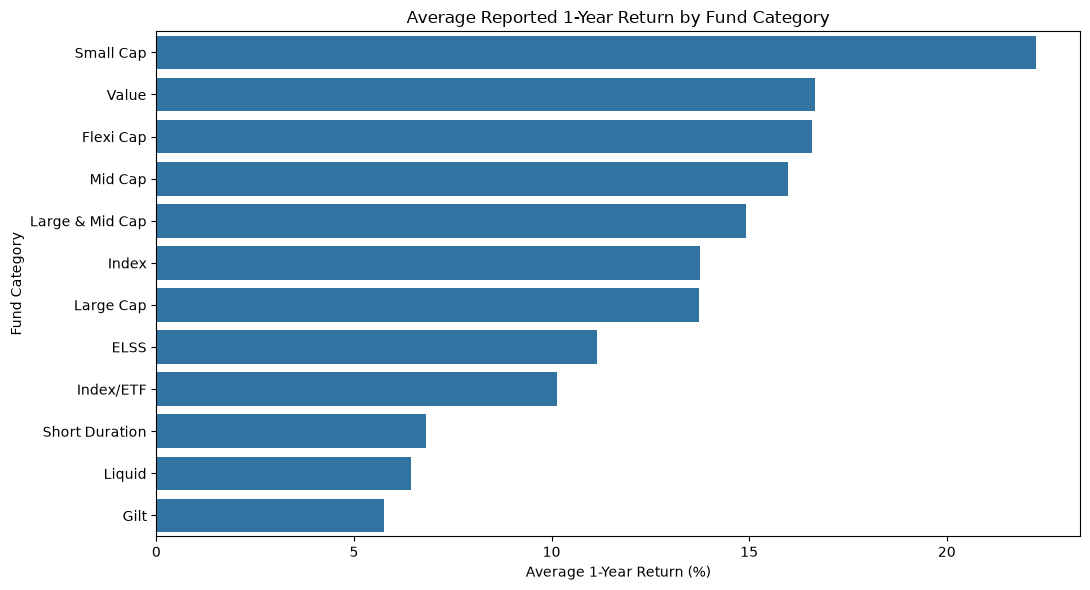

In [7]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=category_analysis.sort_values(
        "avg_1yr_return_pct", ascending=False
    ),
    x="avg_1yr_return_pct",
    y="category"
)

plt.title("Average Reported 1-Year Return by Fund Category")
plt.xlabel("Average 1-Year Return (%)")
plt.ylabel("Fund Category")
plt.tight_layout()
plt.show()

In [8]:
# Year-wise SIP inflow analysis
sip["date"] = pd.to_datetime(sip["date"])

sip["year"] = sip["date"].dt.year

yearly_sip = (
    sip.groupby("year")["sip_inflow_cr"]
    .sum()
    .reset_index(name="total_sip_inflow_cr")
    .sort_values("year")
)

yearly_sip["growth_pct"] = (
    yearly_sip["total_sip_inflow_cr"].pct_change() * 100
)

display(yearly_sip.round(2))

yearly_sip.to_csv(
    REPORTS_DIR / "advanced_yearly_sip_growth.csv",
    index=False
)

print("Saved:", REPORTS_DIR / "advanced_yearly_sip_growth.csv")

KeyError: 'date'

In [9]:
print(sip.columns.tolist())
print(sip.head())

['month', 'sip_inflow_crore', 'active_sip_accounts_crore', 'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct']
        month  sip_inflow_crore  active_sip_accounts_crore  \
0  2022-01-01             11517                       4.91   
1  2022-02-01             11438                       4.93   
2  2022-03-01             12328                       5.09   
3  2022-04-01             11863                       5.48   
4  2022-05-01             12286                       5.55   

   new_sip_accounts_lakh  sip_aum_lakh_crore  yoy_growth_pct  
0                   9.10                4.80             NaN  
1                   8.20                4.85             NaN  
2                  10.50                5.01             NaN  
3                   9.52                5.12             NaN  
4                   8.10                5.15             NaN  


In [10]:
sip["month"] = pd.to_datetime(sip["month"])
sip["year"] = sip["month"].dt.year

yearly_sip = (
    sip.groupby("year")["sip_inflow_crore"]
    .sum()
    .reset_index(name="total_sip_inflow_crore")
    .sort_values("year")
)

yearly_sip["growth_pct"] = (
    yearly_sip["total_sip_inflow_crore"].pct_change() * 100
)

display(yearly_sip.round(2))

yearly_sip.to_csv(
    REPORTS_DIR / "advanced_yearly_sip_growth.csv",
    index=False
)

print("Saved:", REPORTS_DIR / "advanced_yearly_sip_growth.csv")

,year,total_sip_inflow_crore,growth_pct
0,2022,149437,NaN
1,2023,184763,23.64
2,2024,269781,46.01
3,2025,335740,24.45


Saved: C:\Users\asus\mutual-funds-analysis\reports\advanced_yearly_sip_growth.csv


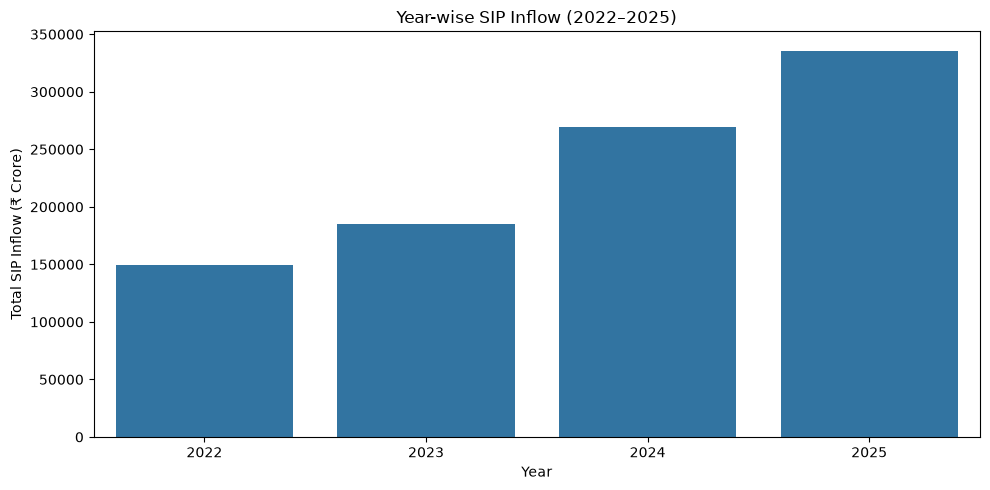

In [11]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_sip,
    x="year",
    y="total_sip_inflow_crore"
)

plt.title("Year-wise SIP Inflow (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Total SIP Inflow (₹ Crore)")
plt.tight_layout()
plt.show()

In [14]:
transaction_analysis = (
    transactions.groupby("transaction_type")
    .agg(
        transaction_count=("transaction_type", "count"),
        total_amount_inr=("amount_inr", "sum"),
        average_amount_inr=("amount_inr", "mean")
    )
    .reset_index()
    .sort_values("transaction_count", ascending=False)
)

display(transaction_analysis.round(2))

transaction_analysis.to_csv(
    REPORTS_DIR / "investor_transaction_analysis.csv",
    index=False
)

print("Saved: investor_transaction_analysis.csv")

,transaction_type,transaction_count,total_amount_inr,average_amount_inr
2,SIP,19716,217233491,11018.13
0,Lumpsum,8095,2059821448,254456.02
1,Redemption,4967,1244525491,250558.79


Saved: investor_transaction_analysis.csv


In [13]:
print(transactions.columns.tolist())
print(transactions.head(3))

['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']
  investor_id transaction_date  amfi_code transaction_type  amount_inr  \
0   INV003054       2024-01-01     119092              SIP        1834   
1   INV002952       2024-01-01     148567       Redemption      392882   
2   INV003420       2024-01-01     118636              SIP         912   

       state       city city_tier age_group  gender  annual_income_lakh  \
0  Telangana  Hyderabad       T30       56+  Female                77.1   
1     Punjab   Amritsar       B30     18-25    Male                 7.1   
2    Haryana  Faridabad       B30     36-45    Male                47.2   

  payment_mode kyc_status  
0          UPI   Verified  
1       Cheque   Verified  
2      Mandate   Verified  


## Advanced Analytics

### 1. Historical Value at Risk (VaR)
The 95% historical daily VaR estimates the loss threshold from the
5th percentile of observed daily NAV returns.

### 2. Investor Cohort Analysis
Investors are grouped by their first transaction month. Monthly active
investors and retention are calculated for each cohort.

### 3. Fund Recommendation Logic
Funds are ranked using Sharpe ratio, annualized return and expense ratio.
Risk categories are grouped into Conservative, Moderate and Aggressive.
This is an illustrative dataset-based ranking, not financial advice.

Generated CSV outputs are saved in the reports folder.


In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

reports = Path("../reports") if Path.cwd().name == "notebooks" else Path("reports")
data = Path("../data/processed") if Path.cwd().name == "notebooks" else Path("data/processed")

print("VaR:", pd.read_csv(reports / "advanced_var_analysis.csv").shape)
print("Cohorts:", pd.read_csv(reports / "investor_cohort_analysis.csv").shape)
print("Recommendations:", pd.read_csv(reports / "fund_recommendations.csv").shape)
